In [11]:
from google.colab import drive, userdata
drive.mount("/content/drive")

try:
    # If the token is already in the environment variable, use it
    if 'tok' not in locals():
        tok = userdata.get("GH_TOKEN")
except Exception as e:
    print("Could not fetch GH_TOKEN from userdata, checking if 'tok' is defined...")
    if 'tok' not in locals():
        raise e

!rm -rf /content/repo
!git clone -q https://{tok}@github.com/mennanasa12-cloud/paradox_perception.git /content/repo
!pip -q install ultralytics pyyaml gdown

!mkdir -p /content/rc && cp /content/drive/MyDrive/paradox/rocks_craters_yolo.zip /content/rc/Dataset_yolo.zip
!cd /content/rc && unzip -q -o Dataset_yolo.zip

# Direct download using the shared Google Drive link ID
!mkdir -p /content/data
!gdown -O /content/data/lunar_processed.zip --id 1LK2p0DsiWJIsnKxvzUTzZYRFpA3d2E3d
!cd /content/data && unzip -q -o lunar_processed.zip

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1LK2p0DsiWJIsnKxvzUTzZYRFpA3d2E3d
From (redirected): https://drive.google.com/uc?id=1LK2p0DsiWJIsnKxvzUTzZYRFpA3d2E3d&confirm=t&uuid=a5d5eef2-4fb0-492f-bcb0-bcf8645b671c
To: /content/data/lunar_processed.zip
100% 1.12G/1.12G [00:16<00:00, 69.7MB/s]


In [2]:
!mkdir -p /content/repo/src/perception/detection
!touch /content/repo/src/perception/detection/__init__.py

In [3]:
%%writefile /content/repo/src/perception/detection/detector.py
from dataclasses import dataclass
from ultralytics import YOLO
from ..utils.config import load_classes

CLASS_NAMES = load_classes()["detection"]   # {0: crater, 1: rock}

@dataclass
class Detection:
    cls_id: int
    cls_name: str
    conf: float
    x1: float
    y1: float
    x2: float
    y2: float

class LunarDetector:
    """YOLOv8s crater + rock detector. Input: BGR uint8 image (OpenCV / cv_bridge 'bgr8')."""
    def __init__(self, weights, conf=0.25, iou=0.5, imgsz=640, device=None):
        self.model = YOLO(weights)
        self.conf, self.iou, self.imgsz, self.device = conf, iou, imgsz, device

    def detect(self, bgr, classes=None):
        r = self.model.predict(bgr, conf=self.conf, iou=self.iou, imgsz=self.imgsz,
                               classes=classes, device=self.device, verbose=False)[0]
        out = []
        for b in r.boxes:
            c = int(b.cls)
            x1, y1, x2, y2 = (float(v) for v in b.xyxy[0])
            out.append(Detection(c, CLASS_NAMES[c], float(b.conf), x1, y1, x2, y2))
        return out

    def detect_craters(self, bgr):
        return self.detect(bgr, classes=[0])

Writing /content/repo/src/perception/detection/detector.py


In [4]:
import json, shutil, yaml
from pathlib import Path
from ultralytics import YOLO

role = json.load(open("/content/drive/MyDrive/paradox/rocks_split.json"))
R, EV = Path("/content/rc/Dataset_yolo"), Path("/content/rc/Dataset_eval")
shutil.rmtree(EV, ignore_errors=True)
(EV/"test"/"images").mkdir(parents=True); (EV/"test"/"labels").mkdir(parents=True)
for s in ["train", "valid", "test"]:
    for p in (R/s/"images").glob("*"):
        if role.get(p.name) == "eval":
            shutil.copy(p, EV/"test"/"images"/p.name)
            lab = R/s/"labels"/(p.stem + ".txt")
            if lab.exists(): shutil.copy(lab, EV/"test"/"labels"/lab.name)
print(len(list((EV/"test"/"images").glob("*"))), "eval images (المتوقع ~1919)")

yaml.safe_dump({"path": str(EV), "train": "test/images", "val": "test/images", "test": "test/images",
                "nc": 2, "names": ["crater", "rock"]}, open("/content/rc/rocks_eval.yaml", "w"))

W = "/content/drive/MyDrive/paradox/checkpoints/yolov8s_rocks_clean/weights/best.pt"
r = YOLO(W).val(data="/content/rc/rocks_eval.yaml", split="test", verbose=False, plots=True)
for i, c in enumerate(r.box.ap_class_index):
    p, rec, ap50, ap = r.box.class_result(i)
    print(f"{r.names[c]:7s} P={p:.3f} R={rec:.3f} AP50={ap50:.3f} AP50-95={ap:.3f}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
1919 eval images (المتوقع ~1919)
Ultralytics 8.4.182 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 603.5±260.7 MB/s, size: 20.3 KB)
val: Scanning /content/rc/Dataset_eval/test/labels... 1919 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1919/1919 1.2Kit/s 1.6s
val: New cache created: /content/rc/Dataset_eval/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 120/120 12.1s/it 24:10
                   all       1919       5938       0.92      0.925       0.96      0.811
Sp

In [6]:
!ls -lh /content/data
!ls /content/drive/MyDrive/paradox
!find /content/data -maxdepth 3 -type d | head -20

total 0
checkpoints  rocks_craters_yolo.zip  rocks_split.json
/content/data


conf>=0.25: {'crater': 1, 'rock': 20}  على 100 صورة
conf>=0.1: {'crater': 3, 'rock': 34}  على 100 صورة
conf>=0.05: {'crater': 8, 'rock': 54}  على 100 صورة
conf>=0.02: {'crater': 9, 'rock': 103}  على 100 صورة
صور فيها crater في الـ GT: 43 | فيها rock: 100
متوسط pixel%: crater 1.30, rock 4.29


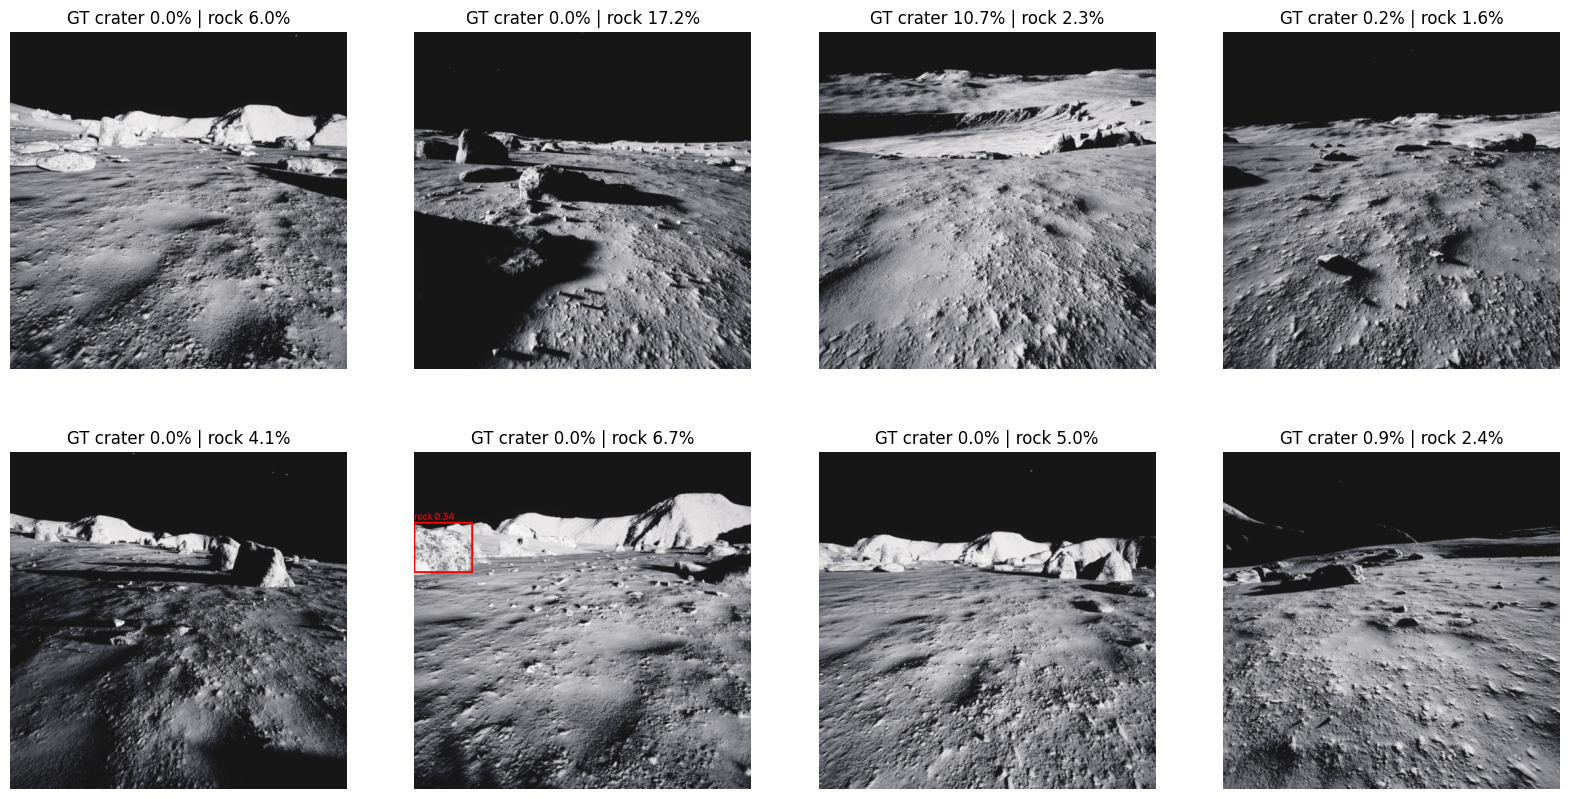

In [14]:
import sys, glob, random, cv2, numpy as np, matplotlib.pyplot as plt
from PIL import Image
sys.path.insert(0, "/content/repo")
from src.perception.detection.detector import LunarDetector

PLOT_CONF = 0.10
det = LunarDetector(W, conf=0.01)   # أقل threshold، وهنفلتر بعدين

image_paths = sorted(glob.glob("/content/data/test/images/*.png") + glob.glob("/content/data/test/images/*.jpg"))
assert image_paths, "/content/data/test/images/ فاضي: راجع فك الـ zip"

def gt_pct(f):
    m = np.array(Image.open(f.replace("/images/", "/masks/")))
    return (m == 1).mean() * 100, (m == 2).mean() * 100   # crater %, rock %

sample = random.Random(1).sample(image_paths, min(100, len(image_paths)))
all_dets = {f: det.detect(cv2.imread(f)) for f in sample}

for t in [0.25, 0.10, 0.05, 0.02]:
    n = {"crater": 0, "rock": 0}
    for ds in all_dets.values():
        for d in ds:
            if d.conf >= t:
                n[d.cls_name] += 1
    print(f"conf>={t}: {n}  على {len(sample)} صورة")

gt = [gt_pct(f) for f in sample]
n_gt_crater = sum(c > 0.1 for c, r in gt)
n_gt_rock = sum(r > 0.1 for c, r in gt)
print(f"صور فيها crater في الـ GT: {n_gt_crater} | فيها rock: {n_gt_rock}")
print(f"متوسط pixel%: crater {np.mean([c for c, r in gt]):.2f}, rock {np.mean([r for c, r in gt]):.2f}")

COL = {"crater": (0, 255, 0), "rock": (0, 0, 255)}
fig, ax = plt.subplots(2, 4, figsize=(20, 10))
for a, f in zip(ax.ravel(), sample[:8]):
    img = cv2.imread(f)
    for d in all_dets[f]:
        if d.conf < PLOT_CONF:
            continue
        cv2.rectangle(img, (int(d.x1), int(d.y1)), (int(d.x2), int(d.y2)), COL[d.cls_name], 2)
        cv2.putText(img, f"{d.cls_name} {d.conf:.2f}", (int(d.x1), max(12, int(d.y1) - 4)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, COL[d.cls_name], 1)
    c, r = gt_pct(f)
    a.set_title(f"GT crater {c:.1f}% | rock {r:.1f}%")
    a.imshow(img[..., ::-1]); a.axis("off")
plt.show()

crater: متوسط 0.7 box/صورة | صور من غير boxes: 79/200
rock: متوسط 4.0 box/صورة | صور من غير boxes: 24/200


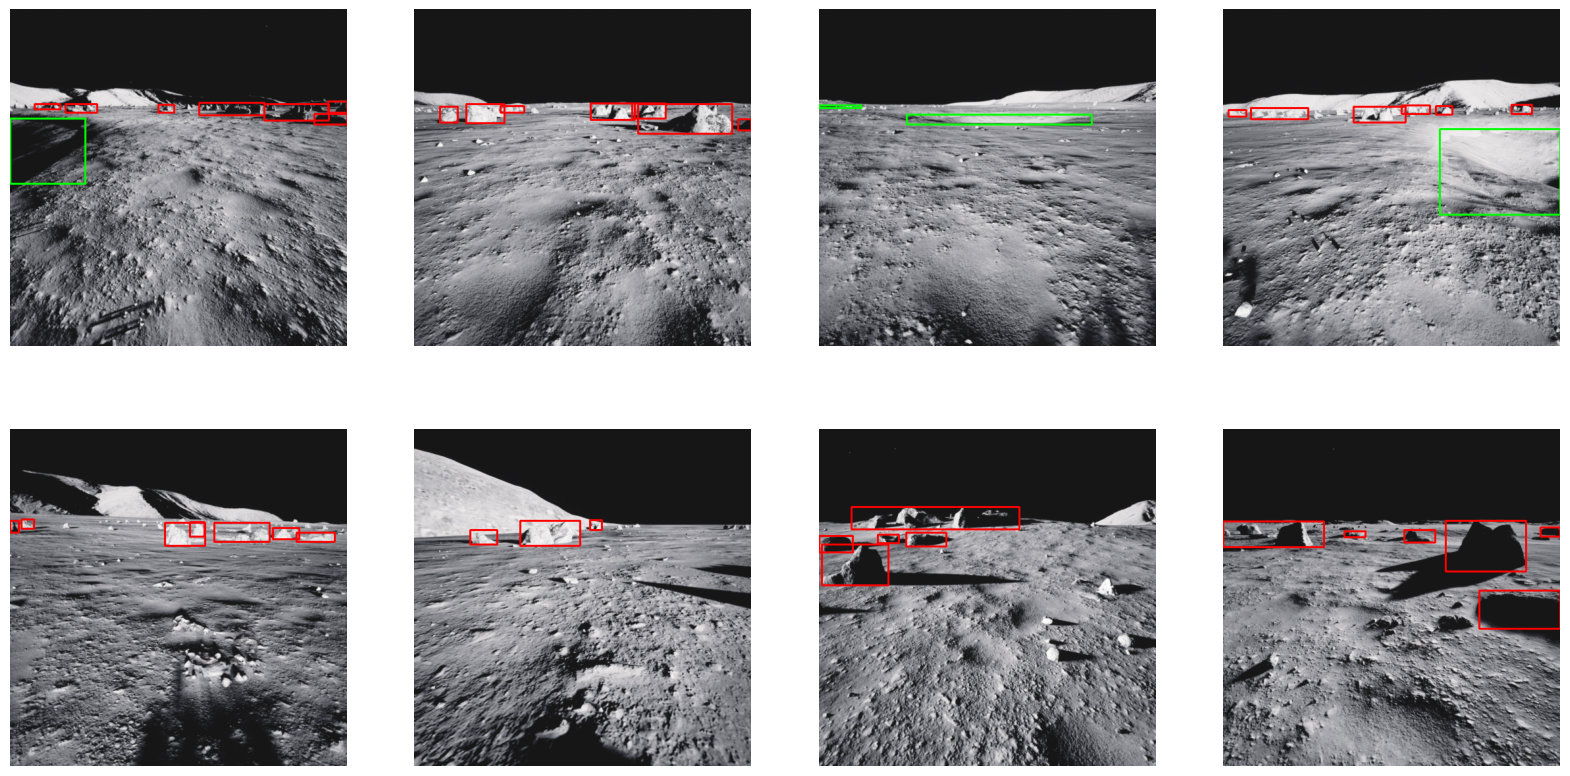

In [15]:
import glob, random, cv2, numpy as np, matplotlib.pyplot as plt
from PIL import Image

MIN_AREA = 150   # pixels على صورة 512x512
NAMES = {1: "crater", 2: "rock"}          # IDs الـ segmentation
COL = {1: (0, 255, 0), 2: (255, 0, 0)}

def boxes_from_mask(m):
    out = []
    for cls in (1, 2):
        n, lab, stats, _ = cv2.connectedComponentsWithStats((m == cls).astype(np.uint8), connectivity=8)
        for i in range(1, n):
            x, y, w, h, a = stats[i]
            if a >= MIN_AREA:
                out.append((cls, x, y, x + w, y + h))
    return out

paths = sorted(glob.glob("/content/data/train/images/*.png"))
sample = random.Random(0).sample(paths, 200)
cnt = {1: [], 2: []}
for f in sample:
    m = np.array(Image.open(f.replace("/images/", "/masks/")))
    bs = boxes_from_mask(m)
    for cls in (1, 2):
        cnt[cls].append(sum(b[0] == cls for b in bs))
for cls in (1, 2):
    print(f"{NAMES[cls]}: متوسط {np.mean(cnt[cls]):.1f} box/صورة | صور من غير boxes: {sum(c == 0 for c in cnt[cls])}/200")

fig, ax = plt.subplots(2, 4, figsize=(20, 10))
for a, f in zip(ax.ravel(), sample[:8]):
    img = cv2.imread(f)
    m = np.array(Image.open(f.replace("/images/", "/masks/")))
    for cls, x1, y1, x2, y2 in boxes_from_mask(m):
        cv2.rectangle(img, (x1, y1), (x2, y2), COL[cls][::-1], 2)
    a.imshow(img[..., ::-1]); a.axis("off")
plt.show()

In [18]:
import os
from pathlib import Path

# Let's check where src/ or detector.py actually are
repo_path = Path("/content/repo")
print("Repo contents:", [str(p.relative_to(repo_path)) for p in repo_path.glob("**/*") if p.is_dir()][:10])

# Ensure the directory exists and write/verify the file
!mkdir -p /content/repo/src/perception/detection
!cp /content/repo/src/perception/detection/detector.py /content/drive/MyDrive/paradox/code_backup/ 2>/dev/null || echo 'Detector not in repo yet'

# Run git commands on the actual changes
!cd /content/repo && git config user.name "mennanasa12-cloud" && git config user.email "mennanasa12-cloud@users.noreply.github.com"
!cd /content/repo && git add . && git commit -m "Add LunarDetector (YOLOv8s crater+rock) and crater evaluation" && git push
!mkdir -p /content/drive/MyDrive/paradox/code_backup && cp /content/repo/src/perception/detection/detector.py /content/drive/MyDrive/paradox/code_backup/ 2>/dev/null || true

Repo contents: ['src', 'notebooks', 'docs', '.git', 'configs', 'src/perception', '.git/hooks', '.git/info', '.git/branches', '.git/logs']
Detector not in repo yet
On branch master
Your branch is up to date with 'origin/master'.

nothing to commit, working tree clean


In [21]:
import os
from pathlib import Path
from google.colab import drive, userdata

# 1. Setup GitHub Credentials safely
try:
    # Reuse existing token from session if available to avoid TimeoutException
    if 'tok' not in globals() and 'tok' not in locals():
        tok = userdata.get("GH_TOKEN")
except Exception as e:
    print("Could not fetch GH_TOKEN from userdata, checking if 'tok' is defined in globals...")
    if 'tok' not in globals():
        raise e

# 2. Re-clone to avoid any local workspace conflicts
!rm -rf /content/repo
!git clone -q https://{tok}@github.com/mennanasa12-cloud/paradox_perception.git /content/repo

# 3. Create target directory inside repository
!mkdir -p /content/repo/src/perception/detection
!touch /content/repo/src/perception/detection/__init__.py

# 4. Write detector.py code inside the repository
detector_code = """from dataclasses import dataclass
from ultralytics import YOLO
from ..utils.config import load_classes

CLASS_NAMES = load_classes()["detection"]   # {0: crater, 1: rock}

@dataclass
class Detection:
    cls_id: int
    cls_name: str
    conf: float
    x1: float
    y1: float
    x2: float
    y2: float

class LunarDetector:
    \"\"\"YOLOv8s crater + rock detector. Input: BGR uint8 image (OpenCV / cv_bridge 'bgr8').\"\"\"
    def __init__(self, weights, conf=0.25, iou=0.5, imgsz=640, device=None):
        self.model = YOLO(weights)
        self.conf, self.iou, self.imgsz, self.device = conf, iou, imgsz, device

    def detect(self, bgr, classes=None):
        r = self.model.predict(bgr, conf=self.conf, iou=self.iou, imgsz=self.imgsz,
                               classes=classes, device=self.device, verbose=False)[0]
        out = []
        for b in r.boxes:
            c = int(b.cls)
            x1, y1, x2, y2 = (float(v) for v in b.xyxy[0])
            out.append(Detection(c, CLASS_NAMES[c], float(b.conf), x1, y1, x2, y2))
        return out

    def detect_craters(self, bgr):
        return self.detect(bgr, classes=[0])
"""

with open("/content/repo/src/perception/detection/detector.py", "w") as f:
    f.write(detector_code)

# 5. Backup detector.py to Google Drive
!mkdir -p /content/drive/MyDrive/paradox/code_backup
!cp /content/repo/src/perception/detection/detector.py /content/drive/MyDrive/paradox/code_backup/detector.py
print("Saved a backup of detector.py to Google Drive.")

# 6. Commit and Push changes to GitHub
!cd /content/repo && git config user.name "mennanasa12-cloud"
!cd /content/repo && git config user.email "mennanasa12-cloud@users.noreply.github.com"
!cd /content/repo && git add src/perception/detection/__init__.py src/perception/detection/detector.py
!cd /content/repo && git commit -m "Add LunarDetector (YOLOv8s crater+rock) and crater evaluation"
!cd /content/repo && git push

Saved a backup of detector.py to Google Drive.
On branch master
Your branch is up to date with 'origin/master'.

nothing to commit, working tree clean
Everything up-to-date
